# Predicting Housing Prices in Buenos Aires

This notebook covers data preparation, cleaning, and exploratory data analysis. Modeling begins after this stage.

## Import Libraries

Import the libraries needed for data preparation and EDA.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# 1. Prepare Data

## 1.1 Import Data

Load both Buenos Aires real-estate extracts and combine them into one dataframe.

In [2]:
file_1 = "data/buenos-aires-real-estate-1.csv"
file_2 = "data/buenos-aires-real-estate-2.csv"

df1 = pd.read_csv(file_1)
df2 = pd.read_csv(file_2)
df = pd.concat([df1, df2], ignore_index=True)

print(f"File 1: {df1.shape}")
print(f"File 2: {df2.shape}")
print(f"Combined dataframe: {df.shape}")

File 1: (8606, 16)
File 2: (8606, 16)
Combined dataframe: (17212, 16)


In [3]:
df.head()

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.0,180000.0,120.0,110.0,1500.000000,1636.363636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...
1,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,250000.0,USD,3790600.0,250000.0,117.0,120.0,2136.752137,2083.333333,NaN,4.0,NaN,http://ramos-mejia.properati.com.ar/s7pd_venta...
2,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,"-34.6497002,-58.658073",410000.0,USD,6216584.0,410000.0,410.0,220.0,1000.000000,1863.636364,NaN,NaN,NaN,http://castelar-moron.properati.com.ar/11vgn_v...
3,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,"-34.5957086,-58.5669503",180000.0,USD,2729232.0,180000.0,200.0,135.0,900.000000,1333.333333,NaN,5.0,NaN,http://tres-de-febrero.properati.com.ar/7f7u_v...
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.6,129000.0,76.0,70.0,1697.368421,1842.857143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...


## 1.2 Initial Inspection

Check column types, duplicate rows, operations, property types, and target availability before cleaning.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17212 entries, 0 to 17211
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   17212 non-null  str    
 1   property_type               17212 non-null  str    
 2   place_with_parent_names     17212 non-null  str    
 3   lat-lon                     13886 non-null  str    
 4   price                       15201 non-null  float64
 5   currency                    15201 non-null  str    
 6   price_aprox_local_currency  15201 non-null  float64
 7   price_aprox_usd             15201 non-null  float64
 8   surface_total_in_m2         11904 non-null  float64
 9   surface_covered_in_m2       14561 non-null  float64
 10  price_usd_per_m2            9747 non-null   float64
 11  price_per_m2                13052 non-null  float64
 12  floor                       2598 non-null   float64
 13  rooms                       9524 non-null 

In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("\nOperations:\n", df["operation"].value_counts(dropna=False))
print("\nProperty types:\n", df["property_type"].value_counts(dropna=False))
print("\nMissing target values:", df["price_aprox_usd"].isna().sum())

Duplicate rows: 0

Operations:
 operation
sell    17212
Name: count, dtype: int64

Property types:
 property_type
apartment    9289
house        6292
PH           1131
store         500
Name: count, dtype: int64

Missing target values: 2011


# 2. Data Cleaning

The cleaning choices below remove invalid records without discarding useful rows solely because optional fields are missing.

## 2.1 Remove Exact Duplicates

Remove exact duplicate rows after combining the files.

In [6]:
before = len(df)
df = df.drop_duplicates().copy()
print(f"Removed {before - len(df):,} duplicate rows")

Removed 0 duplicate rows


## 2.2 Define the Analysis Scope

Keep sale listings with a positive USD price. Records without a target cannot be used for price analysis.

In [ ]:
df["price_aprox_usd"] = pd.to_numeric(df["price_aprox_usd"], errors="coerce")
df = df.loc[
    (df["operation"].eq("sell"))
    & (df["price_aprox_usd"].notna())
    & (df["price_aprox_usd"] > 0)
].copy()

print(f"Rows after scope filter: {len(df):,}")
print(
    f"Price range: ${df['price_aprox_usd'].min():,.0f} to ${df['price_aprox_usd'].max():,.0f}"
)

Rows after scope filter: 15,196
Price range: $5,262 to $15,000,000


## 2.3 Convert Numeric Fields

Convert quantitative columns explicitly so summaries and plots use numeric values.

In [ ]:
numeric_columns = [
    "price",
    "price_aprox_local_currency",
    "price_aprox_usd",
    "surface_total_in_m2",
    "surface_covered_in_m2",
    "price_usd_per_m2",
    "price_per_m2",
    "floor",
    "rooms",
    "expenses",
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

## 2.4 Handle Impossible Measurements

Treat zero or negative areas, room counts, and expenses as missing rather than valid measurements. Missing values are retained for later imputation decisions.

In [ ]:
nonnegative_columns = [
    "surface_total_in_m2",
    "surface_covered_in_m2",
    "rooms",
    "expenses",
]

for column in nonnegative_columns:
    df.loc[df[column] <= 0, column] = np.nan

df.loc[df["floor"] <= 0, "floor"] = np.nan

# Covered area should not exceed total area when both values are available.
invalid_area = (
    df["surface_total_in_m2"].notna()
    & df["surface_covered_in_m2"].notna()
    & (df["surface_covered_in_m2"] > df["surface_total_in_m2"])
)
df.loc[invalid_area, "surface_covered_in_m2"] = np.nan

print(f"Invalid area relationships corrected: {invalid_area.sum():,}")

Invalid area relationships corrected: 290


## 2.5 Extract Geographic Features

Split coordinates and the hierarchical location field into analysis-friendly columns.

In [ ]:
coordinates = df["lat-lon"].str.split(",", n=1, expand=True)
df["latitude"] = pd.to_numeric(coordinates[0], errors="coerce")
df["longitude"] = pd.to_numeric(coordinates[1], errors="coerce")

location_parts = df["place_with_parent_names"].fillna("").str.strip("|").str.split("|")
df["province"] = location_parts.str[1]
df["municipality"] = location_parts.str[2]
df["neighborhood"] = location_parts.str[3]

df[
    [
        "place_with_parent_names",
        "province",
        "municipality",
        "neighborhood",
        "latitude",
        "longitude",
    ]
].head()

,place_with_parent_names,province,municipality,neighborhood,latitude,longitude
0,|Argentina|Capital Federal|Villa Crespo|,Capital Federal,Villa Crespo,NaN,-34.604783,-58.458681
1,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,Bs.As. G.B.A. Zona Oeste,La Matanza,Ramos Mejía,NaN,NaN
2,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,Bs.As. G.B.A. Zona Oeste,Morón,Castelar,-34.649700,-58.658073
3,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,Bs.As. G.B.A. Zona Oeste,Tres de Febrero,NaN,-34.595709,-58.566950
4,|Argentina|Capital Federal|Chacarita|,Capital Federal,Chacarita,NaN,-34.584651,-58.454693


## 2.6 Review Missingness

Do not drop all incomplete rows: floor, expenses, rooms, and coordinates are optional listing attributes.

In [11]:
missing = (
    df.isna()
    .mean()
    .sort_values(ascending=False)
    .mul(100)
    .rename("missing_percent")
    .to_frame()
)
missing.head(12)

,missing_percent
expenses,88.727297
floor,83.758884
neighborhood,49.782838
rooms,44.287971
price_usd_per_m2,35.864701
surface_total_in_m2,35.864701
lat-lon,18.695709
latitude,18.695709
longitude,18.695709
surface_covered_in_m2,16.017373


## 2.7 Modeling-Ready Feature Note

`price_usd_per_m2` and `price_per_m2` are derived from price and area. They are useful for EDA but must be excluded from future price models to prevent target leakage.

In [12]:
leakage_columns = ["price_usd_per_m2", "price_per_m2"]
modeling_exclusions = leakage_columns + ["price_aprox_usd", "properati_url"]
print("Exclude from future predictors:", modeling_exclusions)

Exclude from future predictors: ['price_usd_per_m2', 'price_per_m2', 'price_aprox_usd', 'properati_url']


# 3. Exploratory Data Analysis

Explore price distributions, property mix, size relationships, geographic variation, and missing data.

## 3.1 Descriptive Statistics

Review the cleaned target and main numeric variables.

In [ ]:
eda_columns = [
    "price_aprox_usd",
    "surface_total_in_m2",
    "surface_covered_in_m2",
    "rooms",
    "floor",
    "expenses",
    "latitude",
    "longitude",
]
df[eda_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
price_aprox_usd,15196.0,2.336733e+05,3.239682e+05,5261.560000,90000.000000,145000.000000,260000.000000,1.500000e+07
surface_total_in_m2,9746.0,2.688768e+02,8.521032e+02,10.000000,56.000000,104.000000,261.750000,6.203400e+04
surface_covered_in_m2,12762.0,1.305452e+02,5.877641e+02,1.000000,47.000000,75.000000,155.000000,6.203400e+04
rooms,8466.0,3.017127e+00,1.392687e+00,1.000000,2.000000,3.000000,4.000000,3.100000e+01
floor,2468.0,1.075284e+01,7.445889e+01,1.000000,2.000000,3.000000,6.000000,1.607000e+03
expenses,1713.0,1.169410e+16,4.840003e+17,1.000000,800.000000,1586.000000,3200.000000,2.003200e+19
latitude,12355.0,-3.452016e+01,2.146366e+00,-39.316667,-34.636175,-34.593942,-34.511653,4.133227e+01
longitude,12355.0,-5.856436e+01,1.657759e+00,-122.030796,-58.581385,-58.498143,-58.427066,1.650261e+00


## 3.2 Price Distribution

Housing prices are right-skewed, so inspect both the original and log-transformed scales.

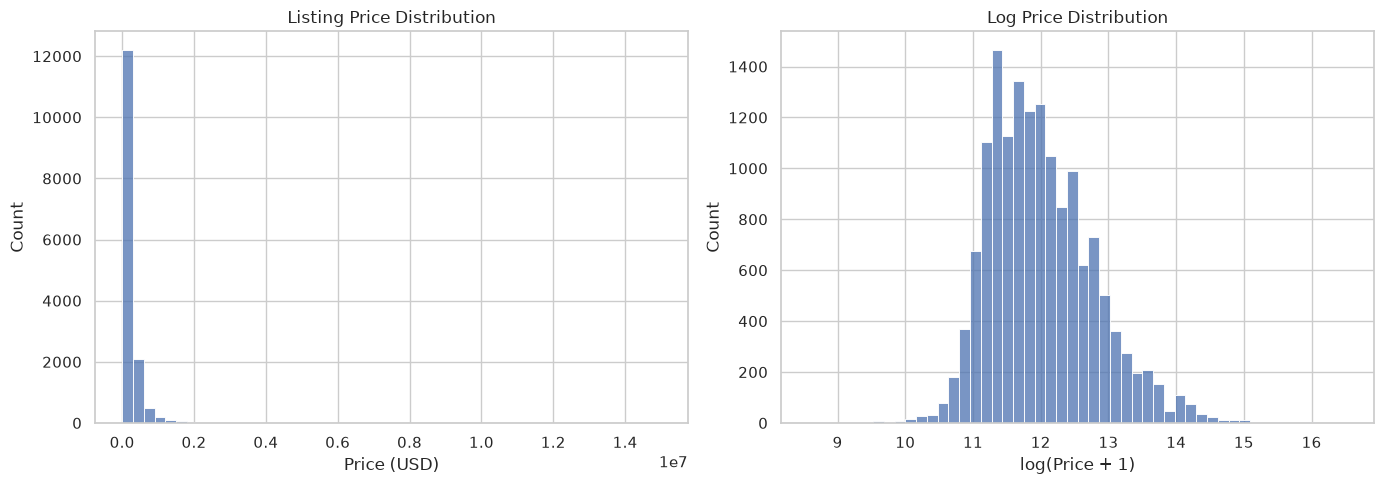

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["price_aprox_usd"], bins=50, ax=axes[0])
axes[0].set_title("Listing Price Distribution")
axes[0].set_xlabel("Price (USD)")

sns.histplot(np.log1p(df["price_aprox_usd"]), bins=50, ax=axes[1])
axes[1].set_title("Log Price Distribution")
axes[1].set_xlabel("log(Price + 1)")

plt.tight_layout()

- 
    - The plots show that Buenos Aires property prices are strongly right-skewed.
        - Raw price distribution: Most listings are concentrated at relatively low prices, while a small number of very expensive properties extend the distribution far to the right, reaching roughly $15 million.
        - The extreme spread compresses most observations near zero, making the raw distribution difficult to interpret visually.
        - Log-transformed prices: The distribution becomes much more balanced and approximately unimodal, centered around  log(price + 1) ≈ 11–12 .
        - A remaining right tail indicates that luxury or unusually expensive listings are still present, but their influence is substantially reduced.
        - This supports using  log(price_aprox_usd)  as a possible modeling target, especially for linear regression, because it can reduce the influence of outliers and improve model fit.
        - For interpretation, predictions on the log scale must later be converted back to USD, and performance should still be reported using dollar-based metrics such as MAE and RMSE.

## 3.3 Property-Type Mix and Prices

Compare the number of listings and price distributions across property types.

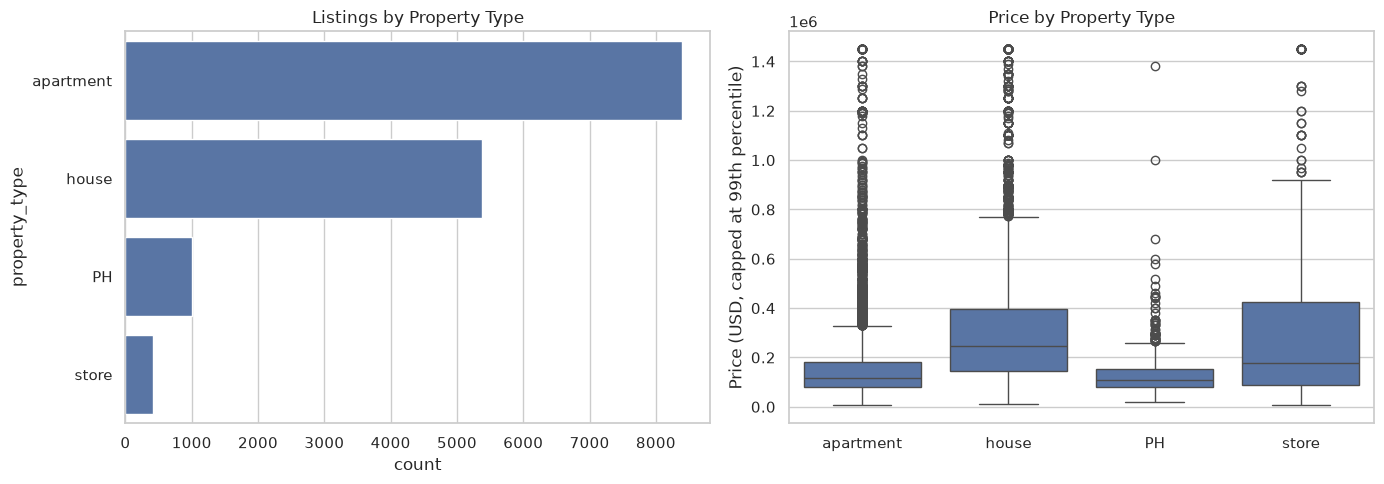

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = df["property_type"].value_counts().index
sns.countplot(data=df, y="property_type", order=order, ax=axes[0])
axes[0].set_title("Listings by Property Type")

plot_df = df.assign(
    price_plot=df["price_aprox_usd"].clip(upper=df["price_aprox_usd"].quantile(0.99))
)
sns.boxplot(data=plot_df, x="property_type", y="price_plot", ax=axes[1])
axes[1].set_title("Price by Property Type")
axes[1].set_xlabel("")
axes[1].set_ylabel("Price (USD, capped at 99th percentile)")

plt.tight_layout()

## 3.4 Price and Property Size

Examine whether larger properties generally have higher listing prices.

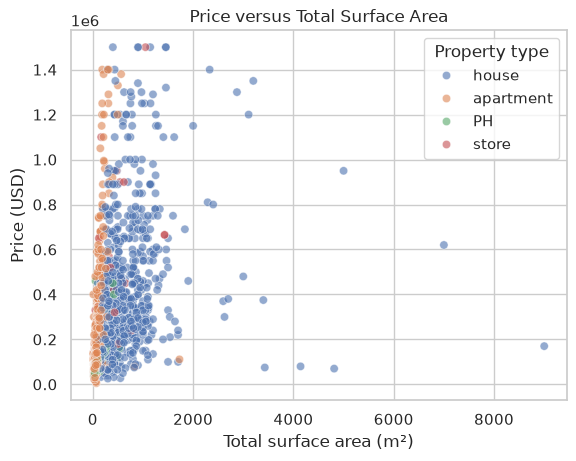

In [ ]:
plot_df = df[["surface_total_in_m2", "price_aprox_usd", "property_type"]].dropna()
plot_df = plot_df[plot_df["surface_total_in_m2"] > 0]
plot_df = plot_df[
    plot_df["price_aprox_usd"] <= plot_df["price_aprox_usd"].quantile(0.99)
]

sns.scatterplot(
    data=plot_df.sample(min(3000, len(plot_df)), random_state=42),
    x="surface_total_in_m2",
    y="price_aprox_usd",
    hue="property_type",
    alpha=0.6,
)
plt.title("Price versus Total Surface Area")
plt.xlabel("Total surface area (m²)")
plt.ylabel("Price (USD)")
plt.legend(title="Property type")
plt.show()

## 3.5 Geographic Price Patterns

Compare median prices across neighborhoods with enough observations for a stable summary.

In [ ]:
province_summary = (
    df.dropna(subset=["province"])
    .groupby("province")
    .agg(
        listings=("price_aprox_usd", "size"), median_price=("price_aprox_usd", "median")
    )
    .query("listings >= 20")
    .sort_values("median_price", ascending=False)
    .head(15)
    .sort_values("median_price")
)

province_summary

,listings,median_price
province,,
Bs.As. G.B.A. Zona Oeste,3353,99000.0
Bs.As. G.B.A. Zona Sur,1352,120000.0
Capital Federal,4638,135000.0
Bs.As. G.B.A. Zona Norte,5853,215000.0


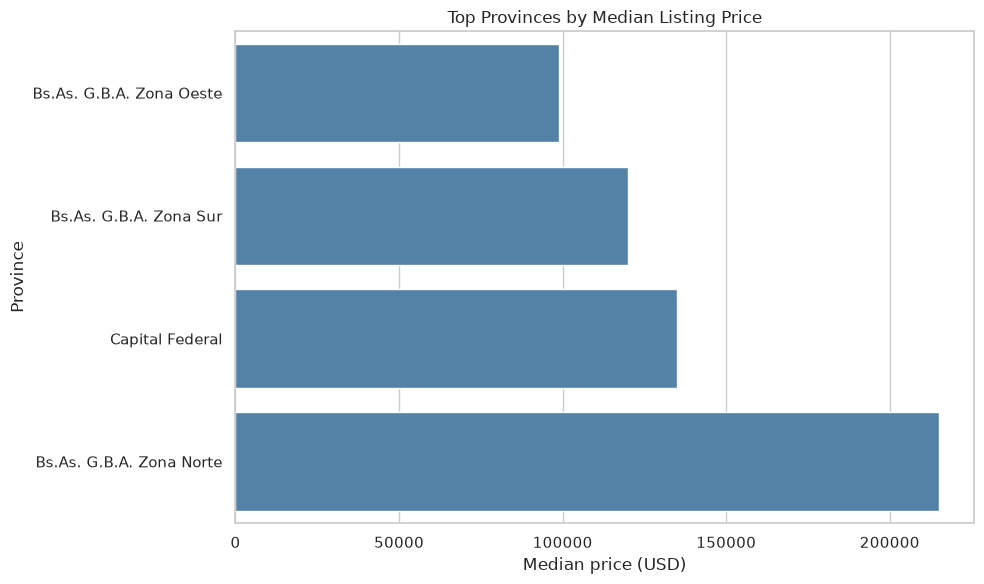

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=province_summary, x="median_price", y=province_summary.index, color="steelblue"
)
plt.title("Top Provinces by Median Listing Price")
plt.xlabel("Median price (USD)")
plt.ylabel("Province")
plt.tight_layout()

## 3.6 Missing-Data Profile

Visualize missingness to guide the later preprocessing and imputation strategy.

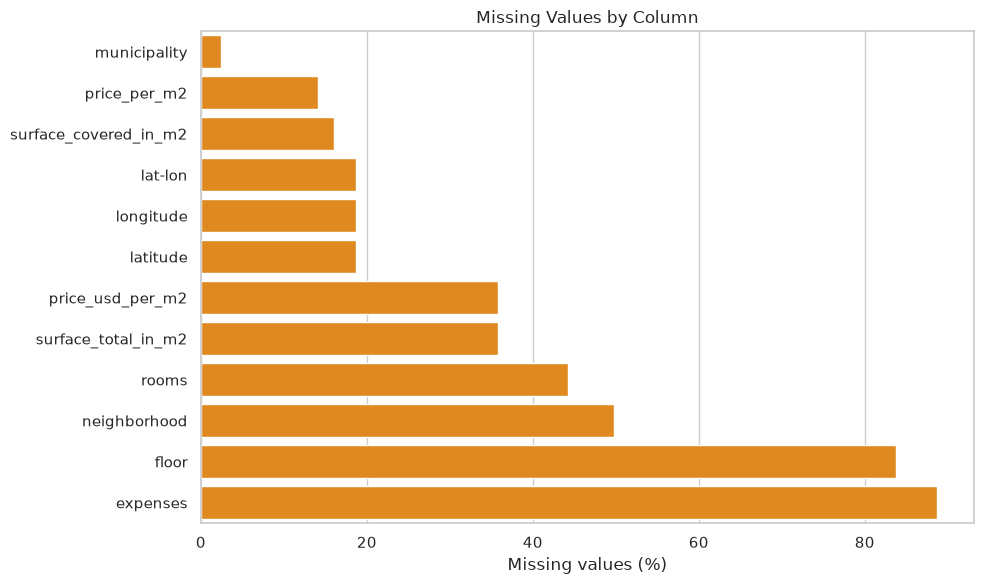

In [22]:
missing_plot = missing.head(12).sort_values("missing_percent")

plt.figure(figsize=(10, 6))
sns.barplot(
    data=missing_plot, x="missing_percent", y=missing_plot.index, color="darkorange"
)
plt.title("Missing Values by Column")
plt.xlabel("Missing values (%)")
plt.ylabel("")
plt.tight_layout()

## EDA Summary

The cleaned dataframe is now ready for the next stage: feature selection, train/test splitting, preprocessing pipelines, and regression modeling.